In [227]:
import os
import json
import xarray as xr
import torch
import torch.nn.functional as F
from datetime import datetime
import numpy as np
import importlib
from matplotlib import pyplot as plt 
import pandas

import dataset
from collate import pad_nextoso_collate
import utils_data

importlib.reload(dataset)
importlib.reload(utils_data)

PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"

In [228]:
dt = dataset.next_oso_Dataset(path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, norm=True, folds=None)
dl = torch.utils.data.DataLoader(dt, batch_size=4, collate_fn=pad_nextoso_collate, shuffle=True)

(<Figure size 1500x800 with 10 Axes>, <Figure size 800x800 with 2 Axes>)

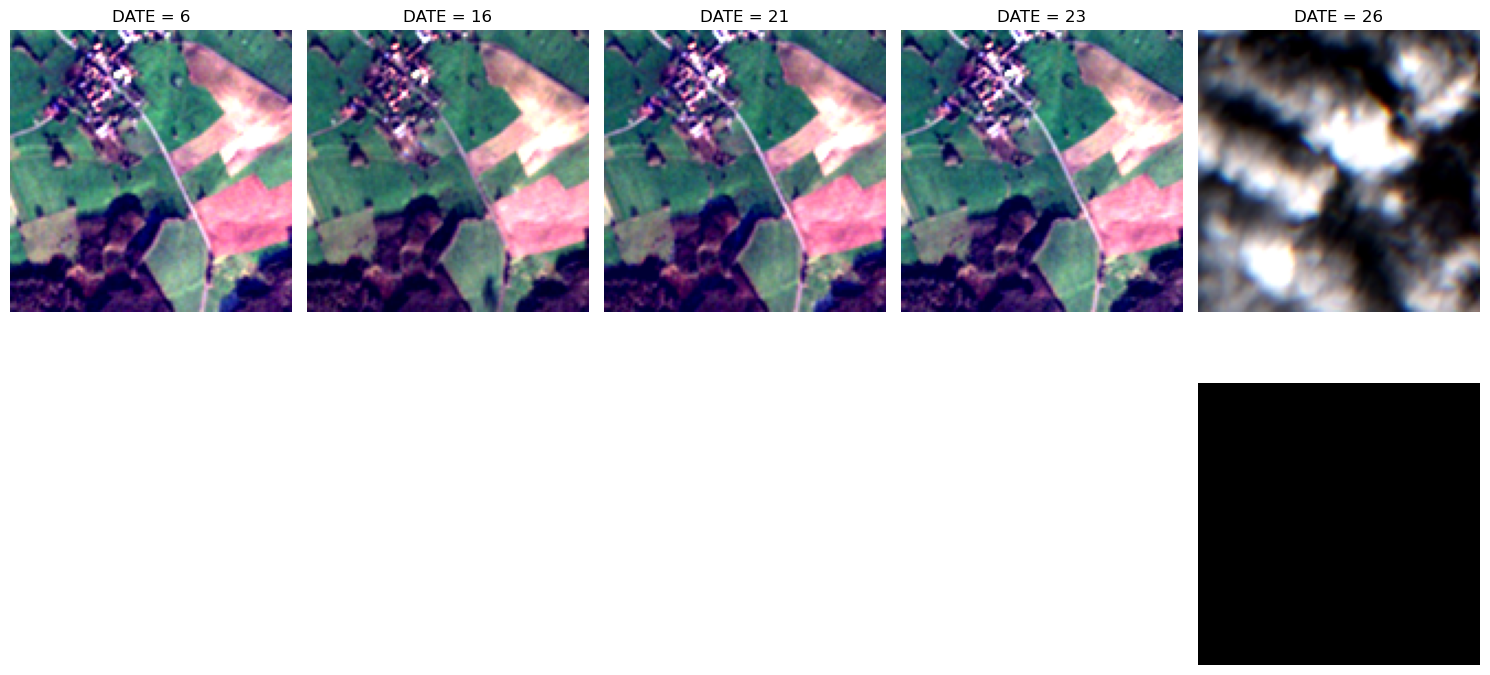

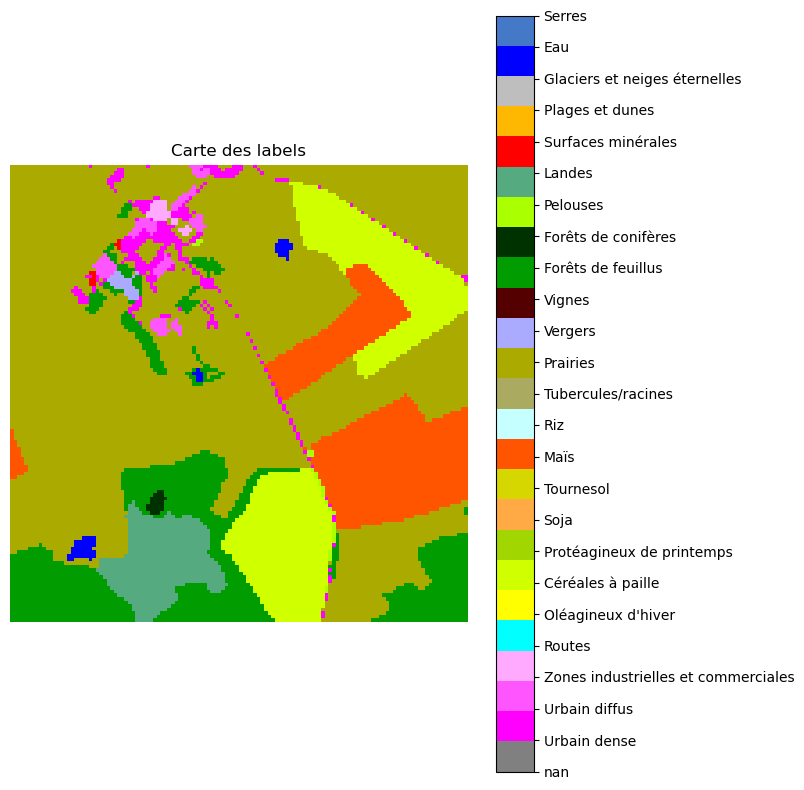

In [229]:
utils_data.plot_nextoso(dt, idx=500, first_date=0)

array([2.1730000e+03, 8.4818200e+05, 1.9274550e+06, 7.0392900e+05,
       1.2956600e+05, 8.3505300e+05, 5.6405550e+06, 5.3720600e+05,
       2.1233700e+05, 6.8763400e+05, 2.9046390e+06, 1.1863400e+05,
       9.2840300e+05, 1.2217791e+07, 4.4714300e+05, 1.4098600e+06,
       1.4515751e+07, 5.3538920e+06, 3.1168000e+06, 2.3764100e+06,
       1.2730390e+06, 1.3403700e+05, 2.9437200e+05, 1.5909660e+06,
       1.0482900e+05])

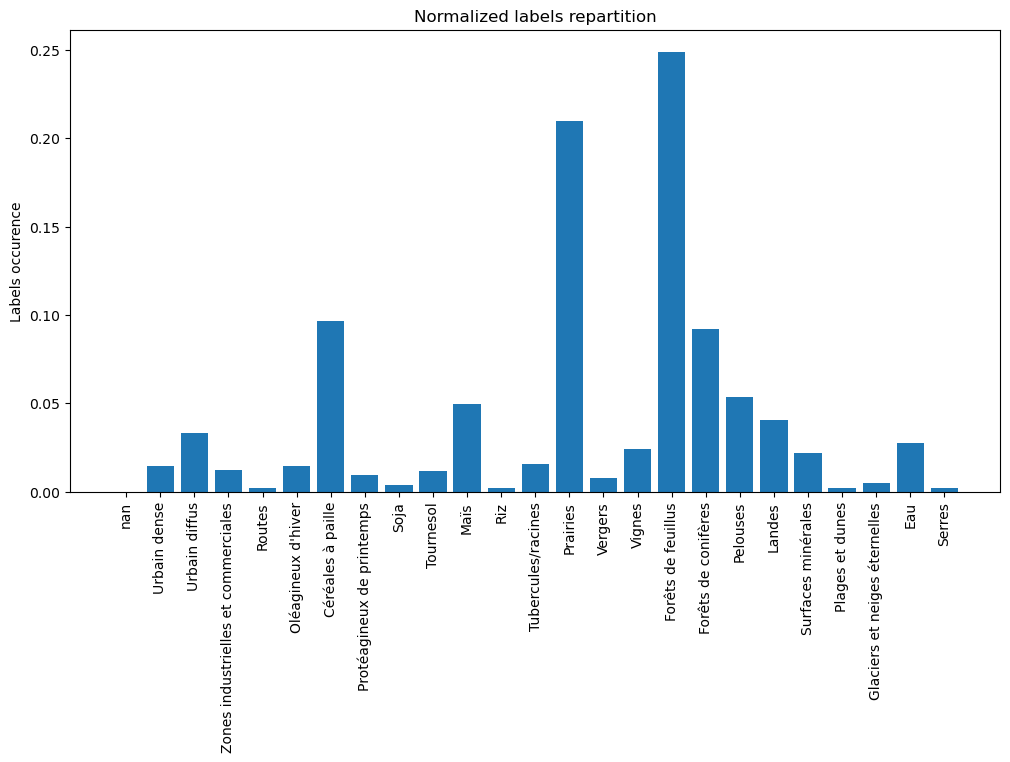

In [ ]:
count = utils_data.count_label(dt)

In [219]:
dt[0][1].flatten().numpy()

array([16, 16, 16, ..., 19, 19, 19], shape=(16384,), dtype=int16)

In [174]:
for i, ((x, dates, mask), y) in enumerate(dl):
    print(x.shape)
    print(dates.shape)
    print(mask.shape)
    print(y.shape)

torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])
torch.Size([4, 10, 148, 128, 128])
torch.Size([4, 148])
torch.Size([4, 148, 128, 128])
torch.Size([4, 128, 128])


KeyboardInterrupt: 

In [ ]:
t_max = 0
for i in range(dt.__len__()):
    if dt[i][0].shape[1] > t_max :
        t_max = dt[i][0].shape[1]

In [13]:
t_max

148

In [170]:
pandas.read_csv(
    "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"
).get('name_class')[1]

'Urbain dense'